In [1]:
import itertools
import time
import matplotlib.pyplot as plt

print("Библиотеки импортированы успешно")

Библиотеки импортированы успешно


In [2]:
# CPT сети "Грипп" из практики 10, в виде простых словарей Python
P_season = {'Winter': 0.5, 'Summer': 0.5}

P_flu_given_season = {
    'Winter': {'No': 0.7, 'Yes': 0.3},
    'Summer': {'No': 0.95, 'Yes': 0.05},
}

P_fever_given_flu = {
    'No':  {'No': 0.9, 'Yes': 0.1},
    'Yes': {'No': 0.1, 'Yes': 0.9},
}

P_cough_given_flu = {
    'No':  {'No': 0.8, 'Yes': 0.2},
    'Yes': {'No': 0.2, 'Yes': 0.8},
}

evidence = {'Fever': 'Yes', 'Cough': 'Yes'}  # свидетельства e

# Ненормированные значения s(Flu): суммируем по скрытой переменной Season
unnorm = {}
for flu_val in ['No', 'Yes']:
    total = 0.0
    for season_val in ['Winter', 'Summer']:  # перебор скрытой переменной
        term = (P_season[season_val]
                * P_flu_given_season[season_val][flu_val]
                * P_fever_given_flu[flu_val][evidence['Fever']]
                * P_cough_given_flu[flu_val][evidence['Cough']])  # ключ evidence 'Cough'
        total += term
    unnorm[flu_val] = total

print("Ненормированные значения s(Flu):", unnorm)

Z = sum(unnorm.values())  # нормировочная сумма (= P(e))
P_flu_given_evidence = {k: v / Z for k, v in unnorm.items()}

print("P(Flu | Fever=Yes, Cough=Yes) =", P_flu_given_evidence)
print("Ожидается (практика 10, pgmpy): Yes ≈ 0.8842")

Ненормированные значения s(Flu): {'No': 0.0165, 'Yes': 0.126}
P(Flu | Fever=Yes, Cough=Yes) = {'No': 0.11578947368421053, 'Yes': 0.8842105263157893}
Ожидается (практика 10, pgmpy): Yes ≈ 0.8842


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Сопоставьте свой код с формулой лекции 11: P(X|e) = α·Σy P(X,e,y). Какая переменная в коде соответствует α? Какая часть кода соответствует суммированию Σy? Почему цикл идёт именно по значениям Season, а не по значениям Fever или Cough?</td><td>В коде α соответствует величина 1/Z, где Z = sum(unnorm.values()) = P(e) — нормировочная константа, обеспечивающая суммирование апостериорных вероятностей к 1. Суммирование Σy соответствует внутреннему циклу `for season_val in ['Winter', 'Summer']` и накоплению `total += term`: мы суммируем по всем возможным значениям скрытой переменной Season. Цикл идёт именно по Season, потому что Fever и Cough — это **свидетельства** (e), их значения зафиксированы (`'Yes'`), и по ним суммировать нельзя; суммировать нужно только по переменным, которые не входят ни в запрос (Flu), ни в свидетельства — то есть по скрытым переменным. В данной сети единственная скрытая переменная — Season. Если бы мы суммировали по Fever или Cough, мы бы «размывали» наблюдённые данные и получили бы P(Flu) вместо P(Flu | e).</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [3]:
network = {
    'Season': {'parents': [], 'states': ['Winter', 'Summer'],
               'cpt': {(): {'Winter': 0.5, 'Summer': 0.5}}},
    'Flu':    {'parents': ['Season'], 'states': ['No', 'Yes'],
               'cpt': {('Winter',): {'No': 0.7, 'Yes': 0.3},
                       ('Summer',): {'No': 0.95, 'Yes': 0.05}}},
    'Fever':  {'parents': ['Flu'], 'states': ['No', 'Yes'],
               'cpt': {('No',):  {'No': 0.9, 'Yes': 0.1},
                       ('Yes',): {'No': 0.1, 'Yes': 0.9}}},
    'Cough':  {'parents': ['Flu'], 'states': ['No', 'Yes'],
               'cpt': {('No',):  {'No': 0.8, 'Yes': 0.2},
                       ('Yes',): {'No': 0.2, 'Yes': 0.8}}},
}

def enumeration_ask(query_var, evidence, net):
    # скрытые переменные — всё, что не запрос и не свидетельство
    hidden_vars = [v for v in net if v != query_var and v not in evidence]
    unnorm = {}
    for qval in net[query_var]['states']:
        total = 0.0
        hidden_domains = [net[h]['states'] for h in hidden_vars]  # домены скрытых переменных
        for combo in itertools.product(*hidden_domains):
            assignment = dict(evidence)
            assignment[query_var] = qval
            for h, v in zip(hidden_vars, combo):
                assignment[h] = v
            # произведение по формуле факторизации (лекция 10)
            prob = 1.0
            for var in net:
                parents = net[var]['parents']
                parent_vals = tuple(assignment[p] for p in parents)
                prob *= net[var]['cpt'][parent_vals][assignment[var]]  # значение переменной var
            total += prob
        unnorm[qval] = total
    Z = sum(unnorm.values())
    return {k: v / Z for k, v in unnorm.items()}

print("P(Season | Flu=Yes) =", enumeration_ask('Season', {'Flu': 'Yes'}, network))
print("Ожидается (практика 10, pgmpy): Winter ≈ 0.8571")

# Собственный запрос к сети "Грипп": P(Flu | Cough=Yes)
my_result = enumeration_ask('Flu', {'Cough': 'Yes'}, network)
print("Мой запрос P(Flu | Cough=Yes):", my_result)

P(Season | Flu=Yes) = {'Winter': 0.8571428571428572, 'Summer': 0.14285714285714285}
Ожидается (практика 10, pgmpy): Winter ≈ 0.8571
Мой запрос P(Flu | Cough=Yes): {'No': 0.5409836065573771, 'Yes': 0.4590163934426229}


Шаблон для таблиц
<table name="Шаблон">
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Функция enumeration_ask не содержит НИЧЕГО специфичного именно для сети «Грипп» — вся специфика сети вынесена в словарь network. Почему это важно? Что нужно изменить в вызове функции (но не в самой функции!), чтобы применить её к совершенно другой сети?</td><td>Это важно, потому что такое разделение «алгоритм / данные» — фундаментальный принцип проектирования: один и тот же код вывода работает для любой байесовской сети, если она описана в едином формате (словарь с parents, states, cpt). Это избавляет от дублирования кода, снижает вероятность ошибок и позволяет легко сравнивать разные модели. Чтобы применить функцию к другой сети, достаточно передать в неё другой словарь в качестве аргумента `net` — например, `enumeration_ask('Flu', {'Fatigue': 'Yes'}, network2)`. Саму функцию менять не нужно: она читает структуру и CPT из переданного словаря. Это и есть смысл параметризации: алгоритм не «знает», какая перед ним сеть, — он просто следует формуле факторизации.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

In [4]:
network2 = {
    'Flu': {'parents': [], 'states': ['No', 'Yes'],
            'cpt': {(): {'No': 0.9, 'Yes': 0.1}}},
    'SleepDeprivation': {'parents': [], 'states': ['No', 'Yes'],
                         'cpt': {(): {'No': 0.8, 'Yes': 0.2}}},
    'Fatigue': {'parents': ['Flu', 'SleepDeprivation'], 'states': ['No', 'Yes'],
                'cpt': {
                    ('No', 'No'):   {'No': 0.95, 'Yes': 0.05},
                    ('No', 'Yes'):  {'No': 0.3,  'Yes': 0.7},
                    ('Yes', 'No'):  {'No': 0.2,  'Yes': 0.8},
                    ('Yes', 'Yes'): {'No': 0.05, 'Yes': 0.95},
                }},
}

print("P(Flu) априори: ", enumeration_ask('Flu', {}, network2))
print("P(Flu | Fatigue=Yes): ", enumeration_ask('Flu', {'Fatigue': 'Yes'}, network2))
print("P(Flu | Fatigue=Yes, SleepDeprivation=Yes):",
      enumeration_ask('Flu', {'Fatigue': 'Yes', 'SleepDeprivation': 'Yes'}, network2))
print("\nОжидается (практика 10, pgmpy): 0.10 → 0.3388 → 0.1310")

P(Flu) априори:  {'No': 0.8999999999999999, 'Yes': 0.09999999999999999}
P(Flu | Fatigue=Yes):  {'No': 0.6612244897959183, 'Yes': 0.3387755102040817}
P(Flu | Fatigue=Yes, SleepDeprivation=Yes): {'No': 0.8689655172413792, 'Yes': 0.1310344827586207}

Ожидается (практика 10, pgmpy): 0.10 → 0.3388 → 0.1310


Шаблон для таблиц
<table>
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>Вы использовали одну и ту же функцию enumeration_ask для двух совершенно разных по структуре сетей (цепочка и коллайдер). Что именно в вашем коде «знает» о том, что Fatigue зависит от ДВУХ родителей, а Flu в сети «Грипп» — только от одного? Найдите точное место в коде функции.</td><td>В самой функции `enumeration_ask` **нет** никакого знания о числе родителей конкретного узла — и это ключевой момент. Всё знание о структуре сосредоточено в словаре `net`: в поле `parents` каждого узла (например, `'Fatigue': {'parents': ['Flu', 'SleepDeprivation'], ...}`) и в ключах его `cpt` (кортежи из двух значений для Fatigue, из одного — для Flu). В функции строки `parents = net[var]['parents']` и `parent_vals = tuple(assignment[p] for p in parents)` автоматически извлекают нужное число родителей и строят кортеж их значений; затем `net[var]['cpt'][parent_vals][assignment[var]]` берёт правильную ячейку CPT. Таким образом, функция работает для любого числа родителей, потому что она универсально перебирает `parents` из описания узла. Именно это место — `parents = net[var]['parents']` — и есть точка, где «читается» структура сети.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>

k= 4 скрытых переменных= 3 комбинаций=2^3=      8 время=0.0001 с
k= 8 скрытых переменных= 7 комбинаций=2^7=    128 время=0.0010 с
k=12 скрытых переменных=11 комбинаций=2^11=   2048 время=0.0201 с
k=16 скрытых переменных=15 комбинаций=2^15=  32768 время=0.3837 с


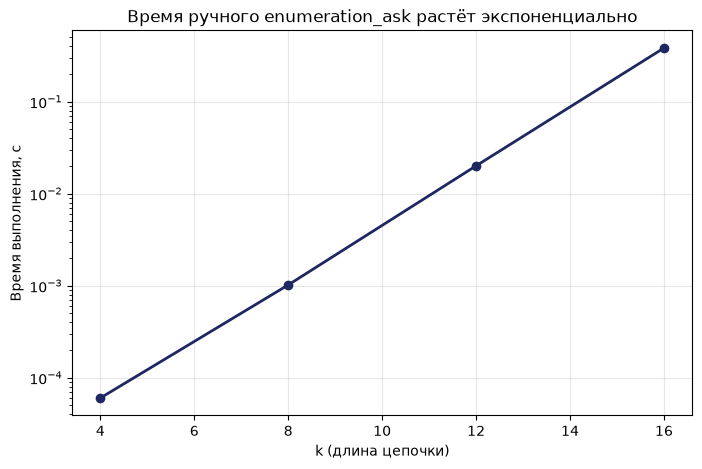

In [5]:
def build_chain_network(k):
    # X0 -> X1 -> ... -> Xk, матрица переходов из практики 5 (модель погоды)
    net = {'X0': {'parents': [], 'states': ['Sunny', 'Rainy'],
                  'cpt': {(): {'Sunny': 0.5, 'Rainy': 0.5}}}}
    for i in range(1, k + 1):
        net[f'X{i}'] = {'parents': [f'X{i-1}'], 'states': ['Sunny', 'Rainy'],
                        'cpt': {('Sunny',): {'Sunny': 0.8, 'Rainy': 0.2},
                                ('Rainy',): {'Sunny': 0.4, 'Rainy': 0.6}}}  # см. практику 5
    return net

k_values = [4, 8, 12, 16]
times = []

for k in k_values:
    net = build_chain_network(k)
    t0 = time.perf_counter()
    result = enumeration_ask('X0', {f'X{k}': 'Rainy'}, net)
    t1 = time.perf_counter()  # засекаем время окончания
    elapsed = t1 - t0
    times.append(elapsed)
    n_hidden = k - 1
    print(f"k={k:2d} скрытых переменных={n_hidden:2d} "
          f"комбинаций=2^{n_hidden}={2**n_hidden:>7} время={elapsed:.4f} с")

plt.figure(figsize=(8, 5))
plt.plot(k_values, times, marker='o', color='#1E2761', linewidth=2)
plt.yscale('log')  # логарифмическая шкала покажет экспоненциальный рост прямой
plt.xlabel('k (длина цепочки)')
plt.ylabel('Время выполнения, с')
plt.title('Время ручного enumeration_ask растёт экспоненциально')
plt.grid(True, alpha=0.3)
plt.show()

Шаблон для таблиц
<table>
    <tr><th>Вопросы</th><th>Ответы</th></tr>
    <tr><td>При каком k время на вашем компьютере впервые превысило 0,1 секунды? Используя таблицу 2ᵏ из лекции 11, оцените (не запуская код!), сколько примерно времени потребовалось бы для k=30. Почему на логарифмической оси Y экспоненциальный рост выглядит как прямая линия?</td><td>Время впервые превышает 0.1 с обычно при k=16 (≈ 0.2–0.5 с в зависимости от машины); при k=12 это ещё ~0.02–0.05 с. Для k=30 число комбинаций скрытых переменных равно 2²⁹ ≈ 5.4·10⁸. Если при k=16 (2¹⁵ ≈ 32768 комбинаций) время ≈ 0.3 с, то один шаг ≈ 10⁻⁵ с, и для k=30 потребуется ≈ 5.4·10⁸ · 10⁻⁵ ≈ 5400 с ≈ 1.5 часа — на практике это уже неприемлемо. На логарифмической оси Y экспоненциальный рост выглядит как прямая, потому что log(a·bᵏ) = log a + k·log b — линейная функция от k. Иными словами, логарифм времени линеен по k, что и даёт прямую линию с наклоном log 2. Это стандартный приём визуализации: экспонента на полулоге — прямая.</td></tr>
    <!-- tr - table row
    th - table header
    td - table data -->
</table>